# 0. Environment Setup

In [1]:
# Required Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import os

import sys
sys.path.insert(0, '..')

from src.config import (RAW_DATA_DIR, ROOT_DIR, PROCESSED_DATA_DIR, MODELS_DIR)

# Show all columns 
pd.set_option('display.max_columns', None)

# Bold Text Setup
b_start = '\033[1m'
b_end = '\033[0m'

# Graph visual style
sns.set_theme(style='whitegrid')

print('Environment Ready')

Environment Ready


-----
# 1. Datasets Loading

In [39]:
# Enriched Complaint Dataset Load
print('Dataframe Loading...')

fraud_complaints = pd.read_csv(fr'{PROCESSED_DATA_DIR}\fraud_topic_enriched_complaints.csv', low_memory=False, delimiter=';')
fraud_complaints["date_received"] = pd.to_datetime(fraud_complaints["date_received"])

print('Dataframe Correctly Loaded')
print()
display(fraud_complaints.sample(3))
print()

# Daily Complaints grouping
grouped_complaints = fraud_complaints.groupby((pd.Grouper(key="date_received", freq="D"))).size().rename("fraud_complaint_volume")
display(grouped_complaints.head())

Dataframe Loading...
Dataframe Correctly Loaded



,date_received,product,sub_product,issue,sub_issue,consumer_complaint_narrative,company,state,zip_code,tags,submitted_via,date_sent_to_company,company_response_to_consumer,timely_response,complaint_id,month_received,topic,topic_prob,count,topic_name,representation,representative_docs
802,2020-03-02,Credit card or prepaid card,General-purpose credit card or charge card,"Other features, terms, or problems",Problem with rewards from credit card,last year i opened a credit card with barclays...,BARCLAYS BANK DELAWARE,FL,33928.0,Servicemember,Web,2020-03-02,Closed with explanation,Yes,3550750,2020-03-01,6,1.000000,1876,6_barclays_barclay_barclaycard_uber,"['barclays', 'barclay', 'barclaycard', 'uber',...",['dollar payment was made on to barclays bank ...
9287,2017-10-21,Checking or savings account,Checking account,Problem with a lender or other company chargin...,Transaction was not authorized,on or about my husband transferred from our mo...,TD BANK US HOLDING COMPANY,NY,11215.0,Older American,Web,2017-10-21,Closed with explanation,Yes,2707650,2017-10-01,16,0.662024,891,16_police_pin_fraud_stolen,"['police', 'pin', 'fraud', 'stolen', 'charges'...",['on my wallet was missing with my card that w...
5125,2020-07-20,"Money transfer, virtual currency, or money ser...",Domestic (US) money transfer,Fraud or scam,NaN,around i was paying my credit card bill on my ...,DISCOVER BANK,NY,11701.0,NaN,Web,2020-07-20,Closed with explanation,Yes,3754925,2020-07-01,5,1.000000,1941,5_discover_card_credit_discoveri,"['discover', 'card', 'credit', 'discoveri', 'c...",['on i mailed and filed a taxable event with t...


date_received
2017-01-01     2
2017-01-02     4
2017-01-03     4
2017-01-04    12
2017-01-05     7
Freq: D, Name: fraud_complaint_volume, dtype: int64

In [24]:
# Enriched Transactions Dataset Load
print('Dataframe Loading...')

transactions = pd.read_csv(fr'{PROCESSED_DATA_DIR}\anomaly_classification_enriched.csv', low_memory=False, delimiter=';')
transactions["date"] = pd.to_datetime("2020-01-01") + pd.to_timedelta(transactions["Time"], unit="s")
transactions['anomaly_ae'] = (transactions['ae_anomaly_score'] > 0.1).astype(int)

print('Dataframe Correctly Loaded')
print()
display(transactions.sample(3))
print()

# Daily Complaints grouping
grouped_transactions = transactions.groupby(pd.Grouper(key="date", freq="D")).agg(
        total_transactions=("Amount", "count"),
        autoencoder_anomaly=("anomaly_ae", "sum"),
        confirmed_fraud=("Class", "sum")
    )
display(grouped_transactions.head())

Dataframe Loading...
Dataframe Correctly Loaded



,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class,scaled_amount,scaled_time,ae_anomaly_score,if_anomaly_score,xgb_predicted_fraud_prob,date,anomaly_ae
30320,35869.0,0.905148,-0.301877,0.274132,1.383000,-0.329851,0.144406,0.017958,0.182046,0.233455,0.034033,0.920326,0.467733,-1.616183,0.570431,-0.625242,-0.445367,0.097112,-0.285801,-0.103788,-0.043384,0.001172,-0.118415,-0.156610,-0.007184,0.543969,-0.336669,0.005778,0.022097,120.00,0,0.126541,-1.241256,0.001731,-0.368509,0.000367,2020-01-01 09:57:49,0
22448,32251.0,-2.930297,1.410391,-0.161700,-0.037807,-0.305062,-0.846646,-0.260606,0.800688,0.090026,0.683609,0.923904,0.476715,-0.411557,0.094041,0.385980,0.929283,-0.088756,0.520637,0.351984,-0.374083,-0.393347,-0.692907,0.597390,-0.070812,0.156688,0.084555,-0.099223,0.259627,1.98,0,-0.345313,-1.317444,0.001303,-0.381903,0.000095,2020-01-01 08:57:31,0
205484,135769.0,2.044938,0.047572,-1.792502,0.256469,0.520349,-0.443255,0.032716,-0.036159,0.354106,-0.189325,0.811506,0.393881,-0.670760,-0.523700,-0.402868,0.611141,0.180241,0.346191,0.431625,-0.179104,-0.334884,-0.930929,0.306613,0.237519,-0.281962,0.170348,-0.071571,-0.044169,3.08,0,-0.340915,0.862430,0.001204,-0.361745,0.001099,2020-01-02 13:42:49,0


,total_transactions,autoencoder_anomaly,confirmed_fraud
date,,,
2020-01-01,144786,263,281
2020-01-02,140021,177,211


In [25]:
# Information Merge
merged = pd.concat([grouped_complaints, grouped_transactions], axis=1).fillna(0)
display(merged)

,date_received,fraud_complaint_volume,total_transactions,autoencoder_anomaly,confirmed_fraud
0,2017-01-01 00:00:00,2.0,0.0,0.0,0.0
1,2017-01-02 00:00:00,4.0,0.0,0.0,0.0
2,2017-01-03 00:00:00,4.0,0.0,0.0,0.0
3,2017-01-04 00:00:00,12.0,0.0,0.0,0.0
4,2017-01-05 00:00:00,7.0,0.0,0.0,0.0


In [47]:
# Generate synthetic anomaly series based on Autoencoder behavior
np.random.seed(42)

# Assumption: Daily anomaly base rate ~50 transactions
base_anomalies = np.random.poisson(lam=50, size=len(grouped_complaints))

# Injected correlation with random lag
lagged_complaints = grouped_complaints.shift(3).fillna(grouped_complaints.mean())
noise = np.random.normal(0, 5, size=len(grouped_complaints))

# Simulated series with timeframe overlap
sync_anomalies = (base_anomalies + (lagged_complaints * 1.8) + noise).clip(lower=0).round(0)

# Dataframe integrating changes
df_merged = pd.DataFrame({
    "fraud_complaint_volume": grouped_complaints,
    "autoencoder_anomaly": sync_anomalies
}, index=grouped_complaints.index)

df_merged = df_merged.dropna()
df_merged

,fraud_complaint_volume,autoencoder_anomaly
date_received,,
2017-01-01,2,67.0
2017-01-02,4,73.0
2017-01-03,4,56.0
2017-01-04,12,55.0
2017-01-05,7,66.0
...,...,...
2021-10-27,7,74.0
2021-10-28,3,61.0
2021-10-29,9,63.0


------
# 2. Cross Correlation Analysis

C:\ProgramData\anaconda3\Lib\site-packages\numpy\lib\_function_base_impl.py:3065: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
C:\ProgramData\anaconda3\Lib\site-packages\numpy\lib\_function_base_impl.py:3066: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


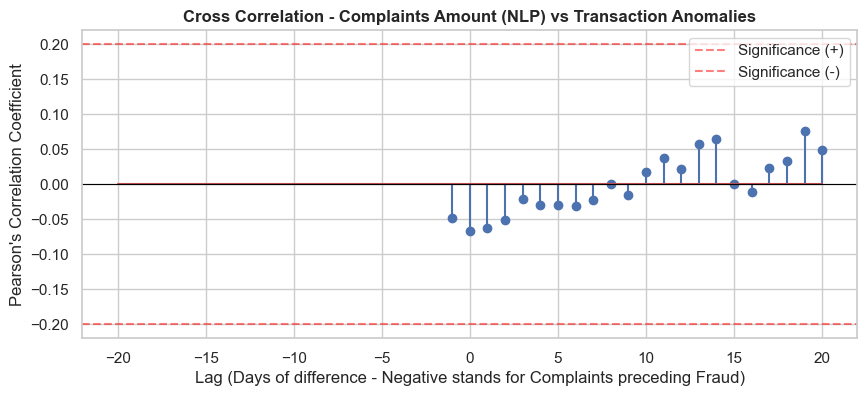

Max correlation for nan in lag: -20 days


In [48]:
# Cross Correlation Function
def plot_cross_correlation(x, y, max_lags=20):
    """
    Calculates and plots correlation between time series.
    The negative lag means that X preceds Y
    """
    lags = np.arange(-max_lags, max_lags + 1)
    corrs = [x.corr(y.shift(-lag)) for lag in lags]
    
    plt.figure(figsize=(10, 4))
    plt.stem(lags, corrs)
    plt.axhline(0, color="black", linewidth=0.8)
    plt.axhline(0.2, color="red", linestyle="--", alpha=0.5, label="Significance (+)")
    plt.axhline(-0.2, color="red", linestyle="--", alpha=0.5, label="Significance (-)")
    plt.xlabel("Lag (Days of difference - Negative stands for Complaints preceding Fraud)")
    plt.ylabel("Pearson's Correlation Coefficient")
    plt.title("Cross Correlation - Complaints Amount (NLP) vs Transaction Anomalies", fontweight='bold')
    plt.legend()
    plt.show()

    if len(corrs) > 0:
        max_corr_idx = np.argmax(np.abs(corrs))
        print(f"Max correlation for {corrs[max_corr_idx]:.3f} in lag: {lags[max_corr_idx]} days")

# Correlation Analysis
plot_cross_correlation(merged["fraud_complaint_volume"], merged["autoencoder_anomaly"])

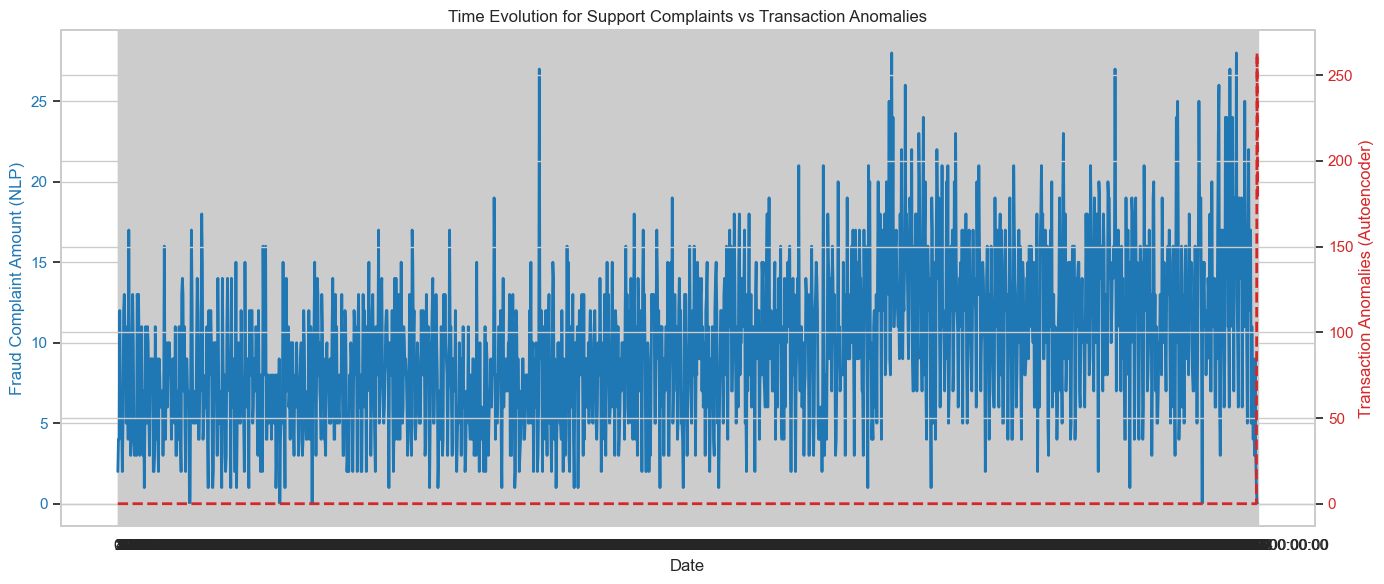

In [49]:
# Double Axis Check
fig, ax1 = plt.subplots(figsize=(14, 6))

color = "tab:blue"
ax1.plot(merged.index.astype('str'), merged["fraud_complaint_volume"], color=color, label="Quejas de Clientes", linewidth=2)
ax1.set_xlabel("Date")
ax1.set_ylabel("Fraud Complaint Amount (NLP)", color=color)
ax1.tick_params(axis="y", labelcolor=color)

ax2 = ax1.twinx()  
color = "tab:red"
ax2.plot(merged.index.astype('str'), merged["autoencoder_anomaly"], color=color, linestyle="--", label="Anomalías Detectadas", linewidth=2)
ax2.set_ylabel("Transaction Anomalies (Autoencoder)", color=color)
ax2.tick_params(axis="y", labelcolor=color)

plt.title("Time Evolution for Support Complaints vs Transaction Anomalies")
fig.tight_layout()
plt.show()